# Descarga e instalacion de librerias y archivos a utilizar

In [ ]:
pip install gdown

In [ ]:
pip install pandas

In [ ]:
!pip install sweetviz

In [ ]:
import os
import gdown

# ID extraído de tu enlace de Google Drive
file_id = "1ENXJDLDOoANo7pZgBvTFCRvImVSwXQ1J"
url = f"https://drive.google.com/uc?id={file_id}"

# Nombre con el que se guardará el archivo en tu carpeta local
filename = "calendar.csv.gz"

# Verificamos si ya existe localmente antes de descargar
if not os.path.exists(filename):
  print(f"Descargando {filename} desde Google Drive...")
  gdown.download(url, filename, quiet=False)
else:
  print(f"El archivo '{filename}' ya existe en el directorio local!")

In [ ]:
import os
import gdown

# ID extraído de tu enlace de Google Drive
file_id = "1JMwdMy8mXA8OgIH9O_6LmbxnWJ7h7e3X"
url = f"https://drive.google.com/uc?id={file_id}"

# Nombre con el que se guardará el archivo en tu carpeta local
filename = "listings.csv.gz"

# Verificamos si ya existe localmente antes de descargar
if not os.path.exists(filename):
  print(f"Descargando {filename} desde Google Drive...")
  gdown.download(url, filename, quiet=False)
else:
  print(f"El archivo '{filename}' ya existe en el directorio local!")

# Lectura de archivos

In [ ]:
import pandas as pd

# Leemos el archivo con Pandas
df_calendar = pd.read_csv("calendar.csv.gz")
df_calendar.head()

In [1]:
import pandas as pd

# Leemos el archivo con Pandas
df_listings = pd.read_csv("listings.csv.gz")
df_listings.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,54019695,https://www.airbnb.com/rooms/54019695,20260629030533,2026-07-02,city scrape,Hermoso departamento con piscina en Puerto Mad...,Enjoy a stylish experience in this centrally-l...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,298874610,...,NaN,NaN,NaN,NaN,NaN,24,24,0,0,NaN
1,41720307,https://www.airbnb.com/rooms/41720307,20260629030533,2026-06-29,city scrape,"Departamento dos ambientes, 2cuadras recoleta ...",Brand new remodeled apartment 2 blocks from th...,NaN,https://a0.muscache.com/pictures/37e687e2-2587...,220409424,...,4.67,4.67,4.56,NaN,NaN,8,8,0,0,0.16
2,1090530711732696379,https://www.airbnb.com/rooms/1090530711732696379,20260629030533,2026-07-02,previous scrape,"alquiler mensual ,escenografico.",This place is strategically located - it will ...,NaN,https://a0.muscache.com/pictures/3adbe27a-af59...,488443857,...,4.67,5.00,4.67,NaN,NaN,3,1,2,0,0.34
3,1482653002662185299,https://www.airbnb.com/rooms/1482653002662185299,20260629030533,2026-07-02,city scrape,Descanso ideal - Av. Sante Fe,"Large and comfortable apartment for 4 people, ...",NaN,https://a0.muscache.com/pictures/hosting/Hosti...,283840529,...,4.95,4.89,4.89,NaN,NaN,12,12,0,0,1.78
4,1046394538968941382,https://www.airbnb.com/rooms/1046394538968941382,20260629030533,2026-06-29,city scrape,Excelente zona,Enjoy easy access to everything from this perf...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,550970409,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN


# Reporte con Sweetviz

## Reporte de Calendar

In [ ]:
import sweetviz as sv

# 4. Generar y guardar el reporte automatizado con Sweetviz
reporte = sv.analyze(df_calendar)
reporte.show_html("reporte_calendar_sweetviz.html")
reporte.show_notebook()

## Reporte de Listings

In [ ]:
import sweetviz as sv

reporte = sv.analyze(df_listings)
reporte.show_html("reporte_listings_sweetviz.html")
reporte.show_notebook()

# Punto 1

## Analisis de datos

**Origen y Contexto de los Datos**

El conjunto de datos analizados corresponde a la oferta de alquileres temporarios en la **Ciudad Autónoma de Buenos Aires (CABA)**. La información proviene del proyecto **Inside Airbnb**, un portal abierto orientado a investigadores, periodistas, formuladores de políticas y grupos comunitarios.

Se trata de una **fuente secundaria** de corte **transversal** (observaciones capturadas en **un único punto fijo en el tiempo**), donde los datos son extraídos mediante **web scraping** directamente de la información pública disponible en la plataforma web de Airbnb. La organización realiza un proceso previo de verificación, limpieza y geocodificación de los anuncios antes de su publicación.

**Limitaciones de la fuente:** Al derivarse de un **scraping** de la oferta pública, el dataset refleja la intención de alquiler (precios de lista y calendarios proyectados por los anfitriones), pero no constituye un registro de transacciones comerciales o reservas efectivas concretadas a puertas cerradas.

## Listings

### Tipo de variables

#### Cualitativas nominales

**Total 29**
* 'id': identificador unico para cada publicacion (listing). 
* 'listing_url': url de cada airnb. 
    * Obervacion: Informacion innecesaria para el trabajo de la base de datos. Eliminar.
* 'scrape_id': Identificador del Scrape que formo parte
    * Observacion: A eliminar la columna, es el mismo id para todas las tuplas
* 'host_location': Ubicación o residencia declarada por el anfitrión
* 'name': Nombre del enlistado (Airbnb)
* 'description': Descripcion detallada sobre el Airbnb   
* 'neighborhood_overview': Descripcion del barrio hecha por el anfrition (Host)
    * Observacion: La columna esta completamente vacia, no aporta informacion. Eliminar.
* 'neighbourhood_cleansed': Barrio oficial al que pertenece cada alojamiento
* 'property_type': Tipo de estructura del inmueble
* 'room_type': Modalidad de privacidad de la estadía
* 'bathrooms_text': Cantidad de baños y descripcion de privacidad
    * Hay que analizar como los tomamos. Podriamos interpretar como 0.5 bathroom = 1 toilette.
    * Para los baños publicos y privados podriamos crear una columna "is_public_bathroom"
* 'amenities': Comodidades que posee el alojamiento. 
    * Observacion: realizar One-Hot Encoding. 
* 'price_quote_raw': Composicion de la cotizacion. 
    * Observacion: Desanidarla en columnas ya que esta en formato JSON.
* 'license': numero de licencia, registro o permiso. 
    * Observacion: a eliminar por un 98% de nulos.
* 'picture_url': URL de la imagen de tamaño estándar del anuncio, alojada en Airbnb.
    * Observacion: innecesario para su analisis. A eliminar.
* 'host_id': Identificador único de Airbnb para el anfitrión/usuario
    * Observacion: innecesario para su analisis. A eliminar.
* 'host_url': La página de Airbnb para el anfitrión.
    * Observacion: innecesario para su analisis. A eliminar.
* 'host_profile_id': Es un identificador único por anfitrión en la plataforma de Airbnb
* 'host_profile_url': Es un identificador o código unívoco asignado a cada usuario/anfitrión registrado en la plataforma
* 'host_name': Nombre del anfitrión. Por lo general, solo el nombre (o los nombres).
* 'host_about': Descripción sobre el anfitrión
    * Observacion: 44% de datos faltantes
* 'host_thumbnail_url': La dirección URL web que almacena y enlaza la versión en miniatura  de la foto de perfil del anfitrión en los servidores de Airbnb.
    * Observacion: A eliminar por 100% de datos faltantes
* 'host_picture_url': La dirección URL web que enlaza a la imagen en tamaño estándar/regular de la foto de perfil del anfitrión en los servidores de Airbnb.
* 'host_neighbourhood': El barrio o vecindario declarado por el propio anfitrión como su zona de residencia o ubicación principal.
    * Observacion: A eliminar por 100% de datos faltantes
* 'host_verifications': La lista o conjunto de canales y métodos de verificación que el anfitrión ha completado y validado en la plataforma de Airbnb (por ejemplo: correo electrónico, teléfono, documento de identidad, correo laboral, etc.)
    * Observacion: A eliminar por 100% de datos faltantes
* 'neighbourhood': El nombre del barrio o zona geográfica asignado a la publicación.
    * Observacion: A eliminar por 100% de datos faltantes
* 'latitude': Utiliza la proyección del Sistema Geodésico Mundial (WGS84) para la latitud y la longitud.
* 'longitude': Utiliza la proyección del Sistema Geodésico Mundial (WGS84) para la latitud y la longitud.
* 'neighbourhood_group_cleansed': Agrupación superior de barrios (comuna, distrito o zona oficial de la ciudad) calculada por geocodificación mediante coordenadas GPS.

#### Cualitativas binarias

**Total 5**
* 'source': Origen o metodo de la recolección de datos 
  * Esta columna indica la vía o método mediante el cual el algoritmo de recolección logró encontrar y verificar esa publicación en la plataforma de Airbnb.
    * **"city scrape"** ("neighbourhood search" en el diccionario): Significa que el anuncio fue encontrado directamente al realizar la búsqueda y rastreo de la ciudad en esta ronda de scraping. Representa la mayoría de la base (27.682 publicaciones, un ~93%).
    * **"previous scrape"**: Significa que la publicación no apareció directamente en la primera busqueda de la ciudad, pero como había sido detectada en un scraping anterior (realizado dentro de los últimos 65 días), se verifico en su URL específica para confirmar que sigue activa y disponible. Ocurre en 2.003 publicaciones (~7%).
    * Es un indicador puramente técnico de recolección no aporta información relevante. Eliminar.
* 'host_is_superhost': Indicador de si el anfitrión posee la categoría de Superhost
* 'host_has_profile_pic': Indicador de si el anfitrión tiene foto de perfil cargada
* 'host_identity_verified': Indicador de si el anfitrión verificó su identidad con documento oficial
* 'has_availability': Indicador de si la propiedad está disponible para ser reservada con true o false.

**Contemplar que todas estas son str, pero hay algunas que son binarias, que luego en el inciso 2 las limpiaremos**

#### Cuantitativas discretas

**Total 30**
* 'last_scraped:' Indica la fecha en la que el algoritmo de recolección automatizada (web scraping) de Inside Airbnb extrajo la información de  
esa publicación puntual desde la web pública de Airbnb.
    * Observacion: El proceso de extracción de datos para esta captura de Buenos Aires o se realizó en un solo segundo, sino que tomó 4 días seguidos (entre el 29 de junio y el 2 de julio de 2026). Eliminar. 
* 'hosts_time_as_user_years': Antigüedad del anfitrión como usuario en la plataforma expresada en años enteros
* 'hosts_time_as_user_months': Antigüedad del anfitrión como usuario en la plataforma expresada en meses enteros
* 'hosts_time_as_host_years': Antigüedad del usuario actuando específicamente como anfitrión expresada en años enteros
* 'hosts_time_as_host_months': Antigüedad del usuario actuando específicamente como anfitrión expresada en meses enteros
* 'host_listings_count': Cantidad total de propiedades que registra el anfitrión en la plataforma
* 'accommodates': Capacidad máxima de huéspedes que admite la propiedad
* 'availability_30': Cantidad de días disponibles para reservar en los próximos 30 días
* 'availability_60': Cantidad de días disponibles para reservar en los próximos 60 días
* 'availability_90': Cantidad de días disponibles para reservar en los próximos 90 días
* 'availability_365': Cantidad de días disponibles para reservar en los próximos 365 días
* 'number_of_reviews': Número total histórico de evaluaciones o reseñas recibidas
* 'number_of_reviews_ltm': Número de evaluaciones recibidas en los últimos 12 meses
* 'number_of_reviews_l30d': Número de evaluaciones recibidas en los últimos 30 días
* 'availability_eoy': Cantidad de días disponibles proyectados hasta el final del año calendario
* 'number_of_reviews_ly': Número de evaluaciones recibidas durante el año anterior
* 'estimated_occupancy_l365d': Estimación de días ocupados en los últimos 365 días
* 'calculated_host_listings_count': Cantidad de publicaciones activas en la ciudad gestionadas por el mismo anfitrión
    * Observacion: a eliminar por una correlacion de 0.99 con "calculated_host_listings_count"
* 'calculated_host_listings_count_entire_homes': Cantidad de casas/departamentos enteros gestionados por el anfitrión
* 'calculated_host_listings_count_private_rooms': Cantidad de habitaciones privadas gestionadas por el anfitrión
* 'calculated_host_listings_count_shared_rooms': Cantidad de habitaciones compartidas gestionadas por el anfitrión
* 'minimum_nights': Número mínimo de noches de estancia para el anuncio.
* 'maximum_nights': Número máximo de noches de estancia para el anuncio.
* 'minimum_minimum_nights': el valor mínimo de noches más bajo del calendario (considerando un horizonte de 365 noches hacia el futuro). 
    * Observacion: A eliminar ya que es igual a minimo de noches.
* 'maximum_minimum_nights': el valor máximo de «noches mínimas» en el calendario (considerando un horizonte de 365 noches hacia el futuro). 
    + Observacion: A charlar su eliminacion por un 0,98 de correlacion.
* 'minimum_maximum_nights': el valor mínimo de «maximum_night» en el calendario (considerando un horizonte de 365 noches hacia el futuro). 
    * Observacion: A charlar su eliminacion por un 0,98 de correlacion.
* 'maximum_maximum_nights': el valor máximo de «maximum_night» en el calendario (considerando un horizonte de 365 noches hacia el futuro). 
    * Observacion: A eliminar ya que es igual a maximum nights.
* 'minimum_nights_avg_ntm': el valor promedio de «noches mínimas» según el calendario (considerando los próximos 365 días). 
    * Observacion: A charlar su eliminacion por objetivo de uso de datos.
* 'maximum_nights_avg_ntm': el valor promedio de «máximo_noche» a partir del calendario (considerando 365 noches hacia el futuro). 
    * Observacion: A charlar su eliminacion por objetivo de uso de datos.
* 'host_total_listings_count': La cantidad total de anuncios o propiedades asociadas al anfitrión en la plataforma de Airbnb a nivel global/general (según los registros de la plataforma).
    * Observacion: A eliminar por 100% de datos faltantes

#### Cuantitativas continuas

**Total 26**
* 'beds': numero de camas. 
    * Observacion: cambiar a integer.
* 'price': precio diario en moneda local. Observacion: cambiar a moneda general para mayor observacion y analisis, por ejemplo, todos los precios en dolares.
* 'price_quote_total_price': precio total que se cotizó para la estancia completa, incluyendo cargos adicionales.
* 'price_quote_price_per_night': precio que cotiza por noche la habitacion.
* 'review_scores_rating': reseñas y calificaciones.
* 'review_scores_accuracy':puntaje promedio que otorgan los huespedes a la propiedad.
* 'review_scores_cleanliness': puntaje sobre la limpieza de la propiedad.
* 'review_scores_checkin': puntaje sobre la experiencia de entrada a la propiedad.
* 'review_scores_communication': puntaje sobre la comunicacion con el anfitrion.
* 'review_scores_location': puntaje sobre la ubicacion.
* 'review_scores_value': puntuación promedio que otorgan los huéspedes sobre la relación precio-calidad.
* 'reviews_per_month': promedio mensual de reseñas por mes.
* 'host_response_rate': El porcentaje de consultas o solicitudes de reserva recibidas que el anfitrión efectivamente responde en la plataforma.
    * Observacion: A eliminar por 100% de datos faltantes
* 'host_acceptance_rate': La tasa a la que un anfitrión acepta solicitudes de reserva.
    * Observacion: A eliminar por 100% de datos faltantes
* 'bathrooms': El número de baños en el anuncio
    * Observaciones: 12% de datos faltantes
* 'bedrooms': Representa el número de dormitorios/habitaciones individuales que posee la propiedad.
* 'estimated_revenue_I365d': ingresos estimados por año.
    * Observacion: tiene un 6% de datos faltantes.
    * Observacion: tiene un 6% de datos faltantes.

#### Variables

In [3]:
# Obtener una lista con los nombres de todas las columnas de tipo texto/string para evaluacion de variables
columnas_str = df_listings.select_dtypes(include=['object', 'string']).columns.tolist() 
# Ver la lista 
print(columnas_str)

['listing_url', 'last_scraped', 'source', 'name', 'description', 'picture_url', 'host_url', 'host_profile_url', 'host_name', 'host_location', 'host_about', 'host_is_superhost', 'host_picture_url', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood_cleansed', 'property_type', 'room_type', 'bathrooms_text', 'amenities', 'price', 'price_quote_checkin_date', 'price_quote_checkout_date', 'price_quote_raw', 'has_availability', 'calendar_last_scraped', 'first_review', 'last_review', 'license']


In [4]:
# Obtener una lista con los nombres de todas las columnas de tipo int y float para evaluacion de variables
columnas_int = df_listings.select_dtypes(include=['integer']).columns.tolist()
columnas_float = df_listings.select_dtypes(include=['float']).columns.tolist()
# Ver la lista 
print(f"variables integer: {columnas_int}\n")
print(f"variables float: {columnas_float}")

variables integer: ['id', 'scrape_id', 'host_id', 'host_profile_id', 'hosts_time_as_user_years', 'hosts_time_as_user_months', 'hosts_time_as_host_years', 'hosts_time_as_host_months', 'host_listings_count', 'accommodates', 'availability_30', 'availability_60', 'availability_90', 'availability_365', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'availability_eoy', 'number_of_reviews_ly', 'estimated_occupancy_l365d', 'calculated_host_listings_count', 'calculated_host_listings_count_entire_homes', 'calculated_host_listings_count_private_rooms', 'calculated_host_listings_count_shared_rooms']

variables float: ['neighborhood_overview', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'neighbourhood', 'neighbourhood_group_cleansed', 'latitude', 'longitude', 'bathrooms', 'bedrooms', 'beds', 'price_quote_total_price', 'price_quote_price_per_ni

In [5]:
#Tipos de datos según Pandas y nulos iniciales
df_listings.info()

<class 'pandas.DataFrame'>
RangeIndex: 29685 entries, 0 to 29684
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            29685 non-null  int64  
 1   listing_url                                   29685 non-null  str    
 2   scrape_id                                     29685 non-null  int64  
 3   last_scraped                                  29685 non-null  str    
 4   source                                        29685 non-null  str    
 5   name                                          29685 non-null  str    
 6   description                                   28917 non-null  str    
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   29684 non-null  str    
 9   host_id                                       29685 non-null  int64  
 1

## Calendar

In [6]:
#Tipos de datos según Pandas. No muestra nulos iniciales debido a la magnitud gigantesca del archivo
df_calendar.info()

<class 'pandas.DataFrame'>
RangeIndex: 10835026 entries, 0 to 10835025
Data columns (total 5 columns):
 #   Column          Dtype
---  ------          -----
 0   listing_id      int64
 1   date            str  
 2   available       str  
 3   minimum_nights  int64
 4   maximum_nights  int64
dtypes: int64(3), str(2)
memory usage: 413.3 MB


**Tipo de variables**

**Cualitativas nominales**:
* 'listing_id': El número de identificación único asignado por Airbnb a la publicación (*listing*) a la cual pertenece cada registro diario de disponibilidad y tarifa.

**Cualitativas binarias**:
* 'available': Indica si el alojamiento se encuentra disponible para recibir reservas en la fecha específica dada por la columna date

**Cualitativas ordinales**:
* 'date': La fecha específica del calendario (dentro del horizonte proyectado a 365 días a partir del raspado) para la cual se registra el estado de disponibilidad (available), la tarifa por noche (price) y las restricciones de estadía mínima y máxima de la propiedad.
    * Observacion: esta como un string, hay que pasarla a tipo fecha. Es ordinal por que la fecha indica un punto exacto en el tiempo, por lo que se tiene un orden segun el dia, el mes y el año.

**Cuantitativas discretas**:
* 'minimum_nights': El número mínimo de noches consecutivas de estancia requeridas por el anfitrión para efectuar una reserva
* 'maximum_nights': El número máximo de noches consecutivas permitidas para una misma estadía

**Cuantitativas continuas**:


## Variables dudosas, total: 9

* 'host_since': La fecha en que se creó el anfitrión o usuario. En el caso de los anfitriones que también son huéspedes de Airbnb, esta podría ser la fecha en que se registraron como huéspedes.
    * Observacion: A eliminar por 100% de datos faltantes
* 'host_response_time': El tiempo promedio o estimado que tarda el anfitrión en responder a los mensajes o solicitudes de reserva efectuadas por los huéspedes en la plataforma
    * Observacion: A eliminar por 100% de datos faltantes
* 'price_quote_checkin_date': fecha de registro en la que se cotizó el precio.
    * Observacion: A definir por formato fecha.
* 'price_quote_checkout_date': fecha de salida solicitada en la cotizacion del precio.
    * Observacion: A definir por formato fecha.
* 'calendar_updated': actualizacion de calendario. 
    * Observacion: A eliminar por un 100% de nulos. A definir por formato fecha.
* 'calendar_last_scraped': fecha en la que se realizó la última extracción de datos del calendario de disponibilidad y tarifas de la propiedad desde la plataforma.
    * Observacion: A definir por formato fecha.
* 'first_review': fecha de primer reseña.
    * Observacion: A definir por formato fecha.
* 'last_review': fecha de ultima reseña.
    * Observacion: A definir por formato fecha.
* 'instant_bookable': si se puede reservar al instante. 
    * Observacion: a eliminar por un 100% de nulos. A definir por formato fecha.

#### Variables

In [ ]:
# Obtener una lista con los nombres de todas las columnas de tipo texto/string para evaluacion de variables
columnas_str = df_listings.select_dtypes(include=['object', 'string']).columns.tolist() 
# Ver la lista 
print(columnas_str)

In [ ]:
# Obtener una lista con los nombres de todas las columnas de tipo int y float para evaluacion de variables
columnas_int = df_listings.select_dtypes(include=['integer']).columns.tolist()
columnas_float = df_listings.select_dtypes(include=['float']).columns.tolist()
# Ver la lista 
print(f"variables integer: {columnas_int}\n")
print(f"variables float: {columnas_float}")

In [ ]:
#Tipos de datos según Pandas y nulos iniciales
df_listings.info()

## Calendar

### Tipo de variables

#### Cualitativas nominales

**Total 1**
* 'listing_id': El número de identificación único asignado por Airbnb a la publicación (*listing*) a la cual pertenece cada registro diario de disponibilidad y tarifa.

#### Cualitativas binarias

**Total 1**
* 'available': Indica si el alojamiento se encuentra disponible para recibir reservas en la fecha específica dada por la columna date


#### Cuantitativas discretas

**Total 2**
* 'minimum_nights': El número mínimo de noches consecutivas de estancia requeridas por el anfitrión para efectuar una reserva
* 'maximum_nights': El número máximo de noches consecutivas permitidas para una misma estadía

#### Cuantitativas continuas

**Total 1**
* 'date': La fecha específica del calendario (dentro del horizonte proyectado a 365 días a partir del raspado) para la cual se registra el estado de disponibilidad (available), la tarifa por noche (price) y las restricciones de estadía mínima y máxima de la propiedad.
    * Observacion: esta como un string, hay que pasarla a tipo fecha.


#### Variables

In [ ]:
#Tipos de datos según Pandas. No muestra nulos iniciales debido a la magnitud gigantesca del archivo
df_calendar.info()

## Analisis Univariado de Variables Principales

### Analisis variable "price"

In [ ]:
import matplotlib.pyplot as plt

# Eliminar texto no numerico a la variable precio que esta en string
precio_texto = ( df_listings['price'] .astype(str) .str.replace('$', '', regex=False) .str.replace(',', '', regex=False) .str.strip() ) 

# Aplicar pd.to_numeric para convertir la serie a float64 
df_listings["price"] = pd.to_numeric(precio_texto, errors='coerce')

# Pasar a float64 con valor numerico normal en dolares
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# Verificar el tipo de dato computacional (debe devolver float64) 
print(df_listings['price'].dtype) 

# Ver las principales métricas de la variable ya numérica 
print(df_listings['price'].describe())

bins=10

# Crear el histograma
plt.hist(df_listings["price"].dropna(), bins=bins, log=True)

# Agregar etiquetas a los ejes
plt.xlabel("Precio por noche")
plt.ylabel("Frecuencia")

# Agregar un título al gráfico
plt.title("Histograma de la variable precio")

# Mostrar el gráfico
plt.show()

# Separar los precios limpios para cada tipo de habitación principales
depto_entero = df_listings[df_listings["room_type"] == "Entire home/apt"]["price"].dropna()
hab_privada = df_listings[df_listings["room_type"] == "Private room"]["price"].dropna()
hab_compartida = df_listings[df_listings["room_type"] == "Shared room"]["price"].dropna()

# Crear el boxplot sin outliers para mejor vista del grafico
plt.figure(figsize=(8, 6))
plt.boxplot([depto_entero, hab_privada, hab_compartida], label=["Depto entero", "Hab. privada", "Hab. compartida"], showfliers=False)

# Agregar etiquetas y título
plt.xlabel("Tipo de Alojamiento (room_type)")
plt.ylabel("Precio por noche ($)")
plt.title("Distribución de Precio por Noche vs. Tipo de Alojamiento")

# Mostrar el gráfico
plt.show()

import numpy as np
import pandas as pd

# Filtrar datos válidos de precio
df_valid = df_listings.dropna(subset=["price"])

def obtener_medidas_boxplot(serie):
    q1 = serie.quantile(0.25)
    q2 = serie.quantile(0.50)  # Mediana
    q3 = serie.quantile(0.75)
    ric = q3 - q1

    lim_inf = q1 - 1.5 * ric
    lim_sup = q3 + 1.5 * ric

    # Valores mínimos y máximos reales
    min_abs = serie.min()
    max_abs = serie.max()

    # Bigotes del boxplot (mínimo y máximo dentro de los límites no atípicos)
    bigote_inf = serie[serie >= lim_inf].min()
    bigote_sup = serie[serie <= lim_sup].max()

    # Conteo de outliers
    num_outliers = (serie < lim_inf) | (serie > lim_sup)
    cant_outliers = num_outliers.sum()
    porc_outliers = (cant_outliers / len(serie)) * 100

    return pd.Series(
        {
            "N (Válidos)": len(serie),
            "Mínimo Absoluto": min_abs,
            "Bigote Inferior": bigote_inf,
            "Q1 (25%)": q1,
            "Mediana (Q2 - 50%)": q2,
            "Q3 (75%)": q3,
            "Bigote Superior": bigote_sup,
            "Máximo Absoluto": max_abs,
            "RIC (Q3 - Q1)": ric,
            "Límite Sup. Outlier": lim_sup,
            "Cant. Outliers": cant_outliers,
            "% Outliers": porc_outliers,
        }
    )

# Calcular para cada tipo de alojamiento (room_type)
tabla_boxplot_room = (
    df_valid.groupby("room_type")["price"]
    .apply(obtener_medidas_boxplot)
    .unstack()
)

# Configurar formato numérico para mejor lectura
pd.set_option("display.float_format", lambda x: '%.2f' % x)

print("=== MEDIDAS DEL BOXPLOT POR TIPO DE ALOJAMIENTO ===")
print(tabla_boxplot_room)


### Analisis variables "accommodates", "bedrooms", "beds" y "bathrooms"

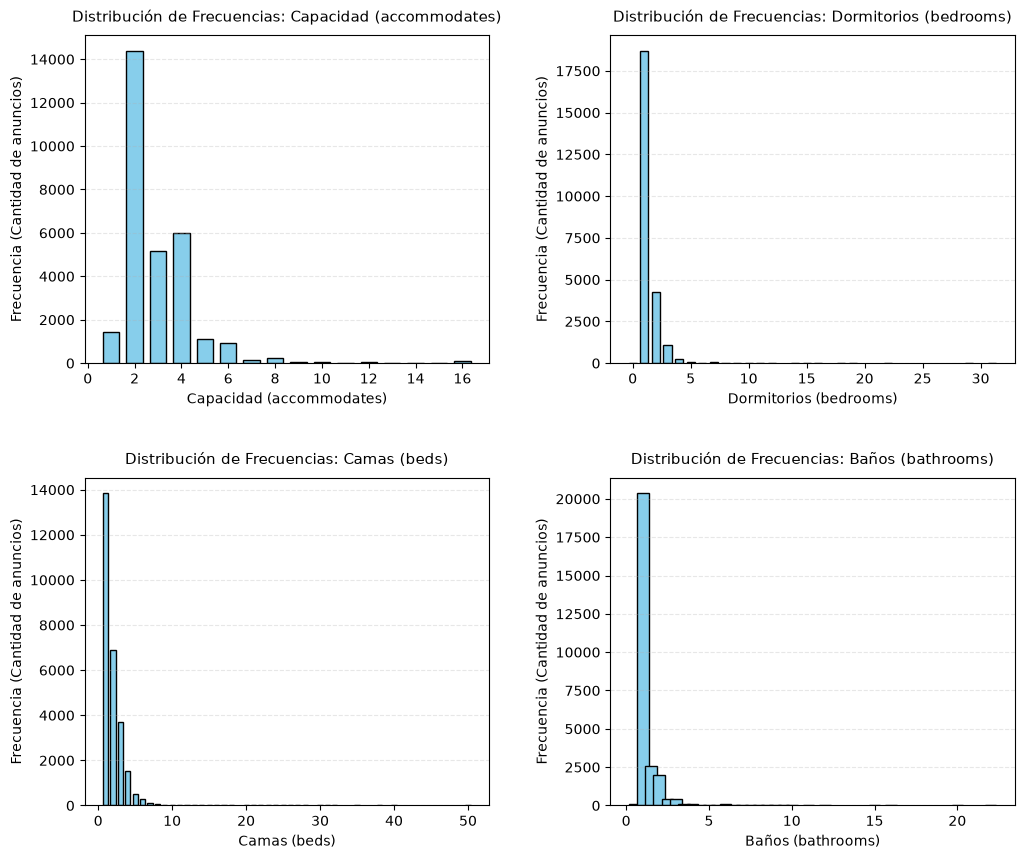

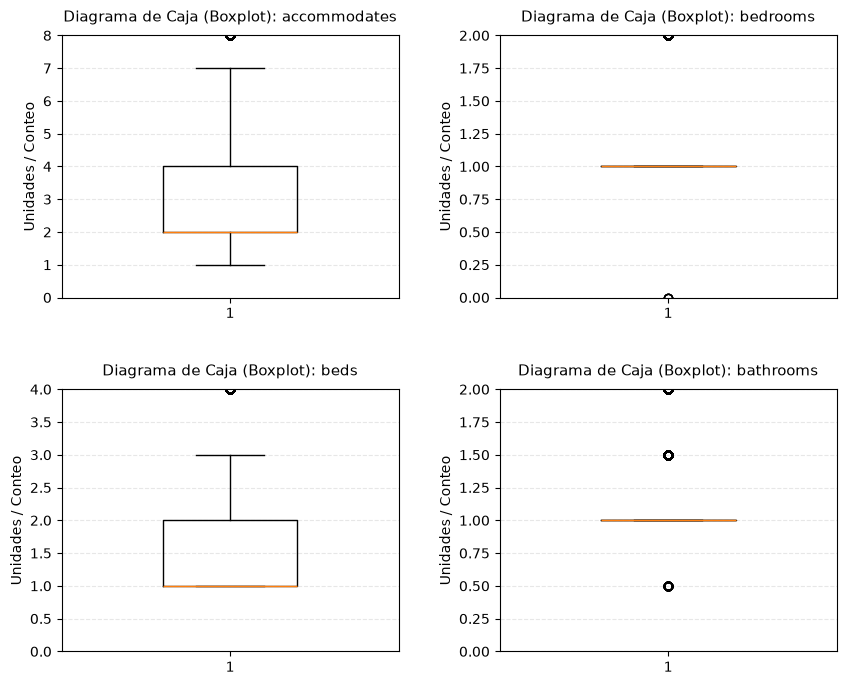

=== TABLA RESUMEN DE MEDIDAS DESCRIPTIVAS Y BOXPLOT (VARIABLES DISCRETAS) ===
              N (Válidos)                                               Moda  \
Variable                                                                       
accommodates        29685  <pandas.core.indexing._iLocIndexer object at 0...   
bedrooms            24500  <pandas.core.indexing._iLocIndexer object at 0...   
beds                27102  <pandas.core.indexing._iLocIndexer object at 0...   
bathrooms           26244  <pandas.core.indexing._iLocIndexer object at 0...   

              Mínimo Absoluto  Q1 (25%)  Mediana (Q2)  Q3 (75%)  RIC (Q3-Q1)  \
Variable                                                                       
accommodates             1.00      2.00          2.00      4.00         2.00   
bedrooms                 0.00      1.00          1.00      1.00         0.00   
beds                     1.00      1.00          1.00      2.00         1.00   
bathrooms                0.50      1.00  

In [26]:
import matplotlib.pyplot as plt
import pandas as pd

# PREPROCESAMIENTO Y EXTRACCION DE VARIABLES
# Asegurar la extracción del número de baños si la columna 'bathrooms' no es numérica
if ("bathrooms" not in df_listings.columns or df_listings["bathrooms"].isnull().all()):
  df_listings["bathrooms"] = (df_listings["bathrooms"].str.extract(r'(\d+\.?\d*)').astype(float))

cols_discretas = ["accommodates", "bedrooms", "beds", "bathrooms"]
nombres_cols = {"accommodates": "Capacidad (accommodates)", "bedrooms": "Dormitorios (bedrooms)", "beds": "Camas (beds)", "bathrooms": "Baños (bathrooms)"}

# GRAFICOS DE BARRAS DE FRECUENCIA DISCRETA
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, col in enumerate(cols_discretas):
  data = df_listings[col].dropna()
  counts = data.value_counts().sort_index()

  axes[i].bar(counts.index, counts.values, color="skyblue", edgecolor="black", width=0.7)
  axes[i].set_title(f"Distribución de Frecuencias: {nombres_cols[col]}", fontsize=11, pad=10)
  axes[i].set_xlabel(nombres_cols[col])
  axes[i].set_ylabel("Frecuencia (Cantidad de anuncios)")
  axes[i].grid(axis="y", linestyle="--", alpha=0.3)

plt.subplots_adjust(hspace=0.35, wspace=0.3)
plt.show()

# BOXPLOTS
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

for i, col in enumerate(cols_discretas):
  data = df_listings[col].dropna()

  # Calcular límites para evitar la compresión del gráfico
  q1 = data.quantile(0.25)
  q3 = data.quantile(0.75)
  ric = q3 - q1
  lim_sup = q3 + 1.5 * ric
  bigote_sup = data[data <= lim_sup].max()

  # Boxplot sin outliers para expandir la vista de la caja
  axes[i].boxplot(data, label=[nombres_cols[col]], showfliers=True, widths=0.4)

  # Ajuste dinámico del eje Y
  axes[i].set_ylim(0, bigote_sup + 1)
  axes[i].set_title(f"Diagrama de Caja (Boxplot): {col}", fontsize=11, pad=10)
  axes[i].set_ylabel("Unidades / Conteo")
  axes[i].grid(axis="y", linestyle="--", alpha=0.3)

plt.subplots_adjust(hspace=0.35, wspace=0.3)
plt.show()

# RESUMEN DE METRICAS Y BOXPLOTS
def obtener_medidas_boxplot_variable(df, columna):
  serie = df[columna].dropna()
  q1 = serie.quantile(0.25)
  q2 = serie.quantile(0.50)  # Mediana
  q3 = serie.quantile(0.75)
  ric = q3 - q1

  lim_inf = q1 - 1.5 * ric
  lim_sup = q3 + 1.5 * ric

  min_abs = serie.min()
  max_abs = serie.max()

  bigote_inf = serie[serie >= lim_inf].min()
  bigote_sup = serie[serie <= lim_sup].max()

  num_outliers = (serie < lim_inf) | (serie > lim_sup)
  cant_outliers = num_outliers.sum()
  porc_outliers = (cant_outliers / len(serie)) * 100

  moda_val = serie.mode().iloc if not serie.mode().empty else None

  return {
      "Variable": columna,
      "N (Válidos)": len(serie),
      "Moda": moda_val,
      "Mínimo Absoluto": min_abs,
      "Q1 (25%)": q1,
      "Mediana (Q2)": q2,
      "Q3 (75%)": q3,
      "RIC (Q3-Q1)": ric,
      "Bigote Superior": bigote_sup,
      "Límite Sup. Outlier": lim_sup,
      "Máximo Absoluto": max_abs,
      "Cant. Outliers": cant_outliers,
      "% Outliers": porc_outliers,
  }

resultados = [
    obtener_medidas_boxplot_variable(df_listings, c) for c in cols_discretas
]
tabla_resumen_discretas = pd.DataFrame(resultados).set_index("Variable")

pd.set_option("display.float_format", lambda x: '%.2f' % x)

print("=== TABLA RESUMEN DE MEDIDAS DESCRIPTIVAS Y BOXPLOT (VARIABLES DISCRETAS)"" ===")
print(tabla_resumen_discretas)

# GUÍA Y DEFINICIÓN DEL ANÁLISIS DE CUARTILES Y OUTLIERS PARA EL INFORME
print("\n" + "=" * 85)
print("GUÍA DE INTERPRETACIÓN Y ANÁLISIS PARA EL INFORME DEL EJERCICIO 1")
print("=" * 85)
print("""
1. MEDIANA (Q2 - 50%):
   - Es el valor central. Indica que el 50% de las propiedades tiene una cantidad menor o igual a este valor.
   - En variables discretas, es preferible a la media ya que representa valores enteros reales y no se distorsiona con outliers.

2. CUARTILES (Q1 = 25% y Q3 = 75%):
   - Q1 (25%): Límite del primer cuarto de los datos. El 25% de la oferta tiene valores menores o iguales a Q1.
   - Q3 (75%): El 75% de las propiedades tiene valores por debajo de Q3, mientras que el 25% superior los supera.

3. RANGO INTERCUARTÍLICO (RIC = Q3 - Q1):
   - Mide la dispersión central del 50% de los datos (la anchura de la caja del boxplot).
   - Un RIC pequeño indica alta concentración alrededor de la mediana (ej. 1 solo dormitorio).

4. DETECCIÓN DE VALORES ATÍPICOS (OUTLIERS):
   - Límite Superior de Outlier = Q3 + (1.5 * RIC). Todo valor por encima de esta cifra se considera atípico.
   - Porcentaje de Outliers (% Outliers): Cuantifica la proporción de propiedades con capacidades o dimensiones atípicamente grandes dentro del mercado de CABA.

5. MODA:
   - Indica la configuración de inmueble más repetida en el mercado (ej. la categoría dominante).
""")
print("=" * 85)

### Analisis variable "room_type"

=== ANÁLISIS DE FRECUENCIAS: room_type ===
                 Frecuencia Absoluta (N)  Frecuencia Relativa (%)
room_type                                                        
Entire home/apt                    26790                    90.25
Private room                        2616                     8.81
Hotel room                           141                     0.47
Shared room                          138                     0.46

Moda de la variable room_type: 0    Entire home/apt
Name: room_type, dtype: str


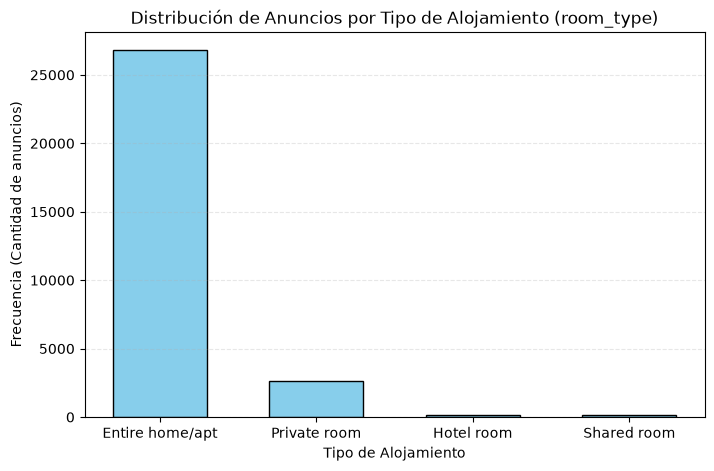

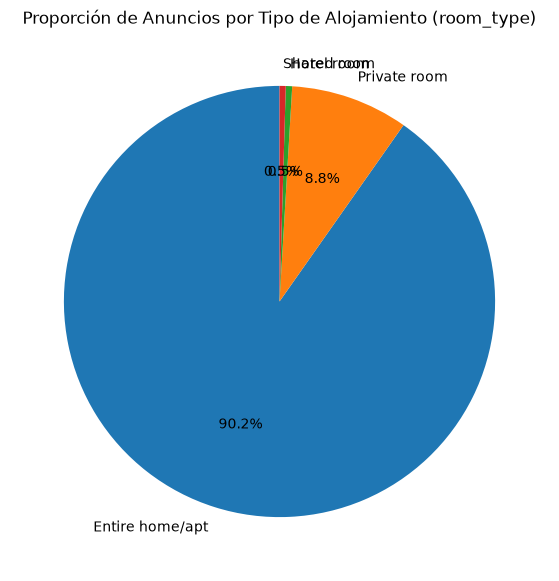

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Calculo de Frecuencias absolutas, frecuencias relativas y moda
room_counts = df_listings["room_type"].value_counts()
total_validos = len(df_listings["room_type"].dropna())

tabla_frecuencias = pd.DataFrame({"Frecuencia Absoluta (N)": room_counts, "Frecuencia Relativa (%)": (room_counts / total_validos) * 100})
moda_room_type = df_listings["room_type"].mode()
pd.set_option("display.float_format", lambda x: "%.2f" % x)

print("=== ANÁLISIS DE FRECUENCIAS: room_type ===")
print(tabla_frecuencias)
print(f"\nModa de la variable room_type: {moda_room_type}")

# Grafico de barras verticales
plt.figure(figsize=(8, 5))
plt.bar(room_counts.index, room_counts.values, color="skyblue", edgecolor="black", width=0.6)
plt.title("Distribución de Anuncios por Tipo de Alojamiento (room_type)", fontsize=12)
plt.xlabel("Tipo de Alojamiento")
plt.ylabel("Frecuencia (Cantidad de anuncios)")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.xticks(rotation=0)
plt.show()

# Grafico de torta
labels = [str(label) for label in room_counts.index]

plt.figure(figsize=(7, 7))
plt.pie(room_counts, labels=labels, autopct="%1.1f%%", startangle=90)
plt.title("Proporción de Anuncios por Tipo de Alojamiento (room_type)")
plt.show()

### Analisis variable "neighbourhood_cleansed"

=== ANÁLISIS DE LA VARIABLE: neighbourhood_cleansed ===
Número de barrios únicos: 48
Moda (Barrio con más publicaciones): <pandas.core.indexing._iLocIndexer object at 0x7f4fa3d896d0>
Concentración acumulada Top 3 barrios: 54.29%  (Palermo, Recoleta, San Nicolas)
Concentración acumulada Top 5 barrios: 64.18%  (Palermo, Recoleta, San Nicolas, Retiro, Monserrat)

--- Tabla de los Top 10 Barrios con mayor cantidad de anuncios ---
                        Frecuencia Absoluta (N)  Frecuencia Relativa (%)  \
neighbourhood_cleansed                                                     
Palermo                                    9703                    32.69   
Recoleta                                   4090                    13.78   
San Nicolas                                2322                     7.82   
Retiro                                     1485                     5.00   
Monserrat                                  1451                     4.89   
Belgrano                              

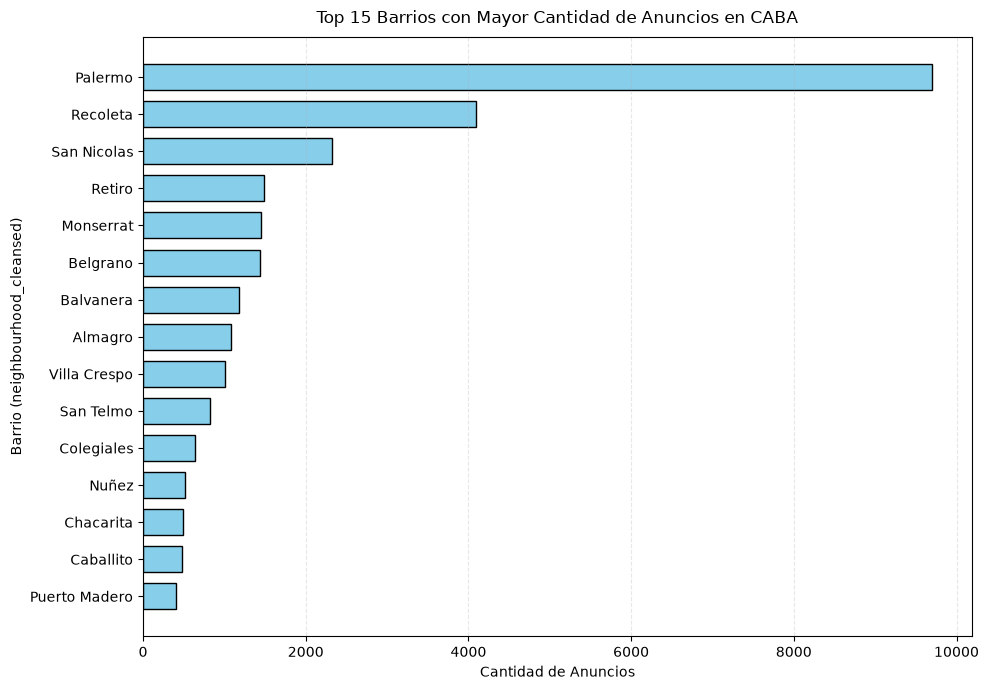

In [28]:
import matplotlib.pyplot as plt
import pandas as pd

# CALCULO DE METRICAS Y FRECUENCIAS
barrios_series = df_listings["neighbourhood_cleansed"].dropna()
total_anuncios = len(barrios_series)

# Número de barrios únicos (cardinalidad total)
barrios_unicos = barrios_series.nunique()

# Moda (Barrio con mayor cantidad de anuncios)
moda_barrio = barrios_series.mode().iloc

# Frecuencias absolutas y relativas por barrio
frecuencias_barrios = barrios_series.value_counts()
porcentajes_barrios = (frecuencias_barrios / total_anuncios) * 100

# Porcentaje de concentración acumulada (Top 3 y Top 5 barrios)
conc_top3 = porcentajes_barrios.iloc[:3].sum()
conc_top5 = porcentajes_barrios.iloc[:5].sum()

print("=== ANÁLISIS DE LA VARIABLE: neighbourhood_cleansed ===")
print(f"Número de barrios únicos: {barrios_unicos}")
print(f"Moda (Barrio con más publicaciones): {moda_barrio}")
print(f"Concentración acumulada Top 3 barrios: {conc_top3:.2f}%", f" ({', '.join(frecuencias_barrios.index[:3])})")
print(f"Concentración acumulada Top 5 barrios: {conc_top5:.2f}%", f" ({', '.join(frecuencias_barrios.index[:5])})")

print("\n--- Tabla de los Top 10 Barrios con mayor cantidad de anuncios ---")
tabla_top10 = pd.DataFrame({"Frecuencia Absoluta (N)": frecuencias_barrios.head(10), "Frecuencia Relativa (%)": porcentajes_barrios.head(10), "Porcentaje Acumulado (%)": porcentajes_barrios.head(10).cumsum()})
pd.set_option("display.float_format", lambda x: "%.2f" % x)
print(tabla_top10)

# GRAFICO DE GRAFICAS HORIZONTALES
top_15 = frecuencias_barrios.head(15).sort_values(ascending=True)

plt.figure(figsize=(10, 7))
plt.barh(top_15.index, top_15.values, color="skyblue", edgecolor="black", height=0.7)

plt.title("Top 15 Barrios con Mayor Cantidad de Anuncios en CABA", fontsize=12, pad=10)
plt.xlabel("Cantidad de Anuncios")
plt.ylabel("Barrio (neighbourhood_cleansed)")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

### Analisis variables "host_is_superhost" y "instant_bookable"

=== ANÁLISIS DE FRECUENCIAS: Es Superhost (host_is_superhost) ===
                   Frecuencia Absoluta (N)  Frecuencia Relativa (%)
host_is_superhost                                                  
No                                   17492                    58.93
Sí                                   12193                    41.07
Moda: No

=== ANÁLISIS DE FRECUENCIAS: Reserva Inmediata (instant_bookable) ===
Empty DataFrame
Columns: [Frecuencia Absoluta (N), Frecuencia Relativa (%)]
Index: []
Moda: N/A



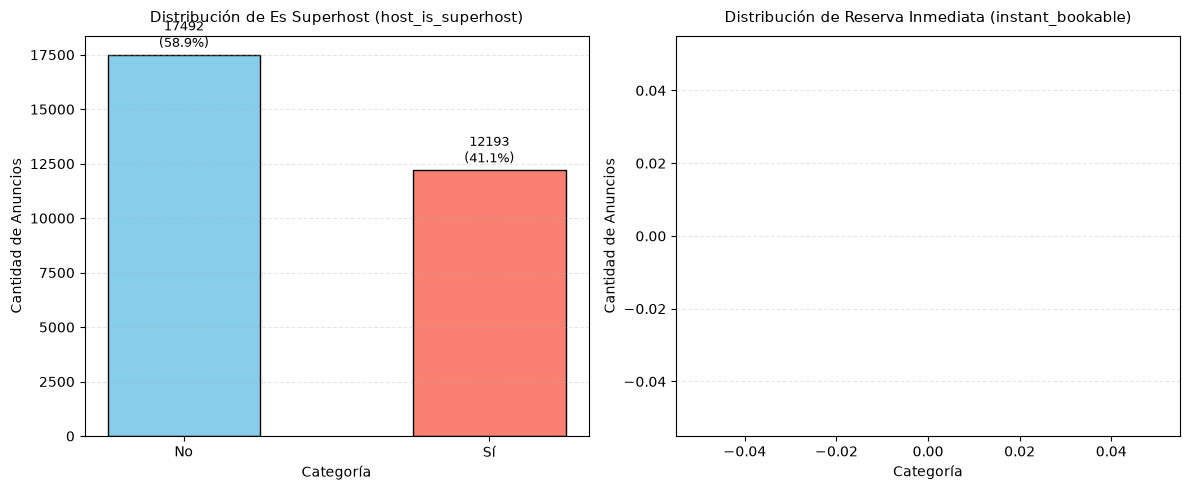

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# CALCULO DE FRECUENCIAS ABSOLUTAS Y RELATIVAS
cols_binarias = ["host_is_superhost", "instant_bookable"]
nombres_cols = {"host_is_superhost": "Es Superhost (host_is_superhost)", "instant_bookable": "Reserva Inmediata (instant_bookable)"}

for col in cols_binarias:
  # Normalizar valores ("t"/"f" o booleanos) a etiquetas "Sí" / "No"
  serie = df_listings[col].dropna().astype(str).str.lower().str.strip()
  serie = serie.map({"t": "Sí", "f": "No", "true": "Sí", "false": "No"}).fillna(serie)

  abs_freq = serie.value_counts()
  rel_freq = (abs_freq / len(serie)) * 100

  tabla = pd.DataFrame({"Frecuencia Absoluta (N)": abs_freq, "Frecuencia Relativa (%)": rel_freq})

  pd.set_option("display.float_format", lambda x: '%.2f' % x)
  print(f"=== ANÁLISIS DE FRECUENCIAS: {nombres_cols[col]} ===")
  print(tabla)
  print(f"Moda: {serie.mode().iloc[0] if not serie.mode().empty else 'N/A'}\n")

# GRAFICOS DE BARRAS
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for i, col in enumerate(cols_binarias):
  serie = df_listings[col].dropna().astype(str).str.lower().str.strip()
  serie = serie.map({"t": "Sí", "f": "No", "true": "Sí", "false": "No"}).fillna(serie)

  abs_freq = serie.value_counts()

  axes[i].bar(abs_freq.index, abs_freq.values, color=["skyblue", "salmon"], edgecolor="black", width=0.5)
  axes[i].set_title(f"Distribución de {nombres_cols[col]}", fontsize=11, pad=10)
  axes[i].set_xlabel("Categoría")
  axes[i].set_ylabel("Cantidad de Anuncios")
  axes[i].grid(axis="y", linestyle="--", alpha=0.3)

  # Agregar etiquetas numéricas y porcentajes sobre cada barra
  total = len(serie)
  for j, val in enumerate(abs_freq.values):
    pct = (val / total) * 100
    axes[i].text(
        j,
        val + (max(abs_freq.values) * 0.01),
        f'{val}\n({pct:.1f}%)',
        ha="center",
        va="bottom",
        fontsize=9,
    )

plt.tight_layout()
plt.show()

### Analisis variable "calculated_host_listings_count"

=== ANÁLISIS DE LA VARIABLE: calculated_host_listings_count (MULTIPROPIEDAD) ===
N (Válidos): 29685
Q1 (25%): 1.00
Mediana (Q2 - 50%): 3.00
Q3 (75%): 12.00
Rango Intercuartílico (RIC): 11.00
Anuncios en Multipropiedad (>1 listing): 18877 (63.59%)
Anuncios de Propietario Único (=1 listing): 10808 (36.41%)


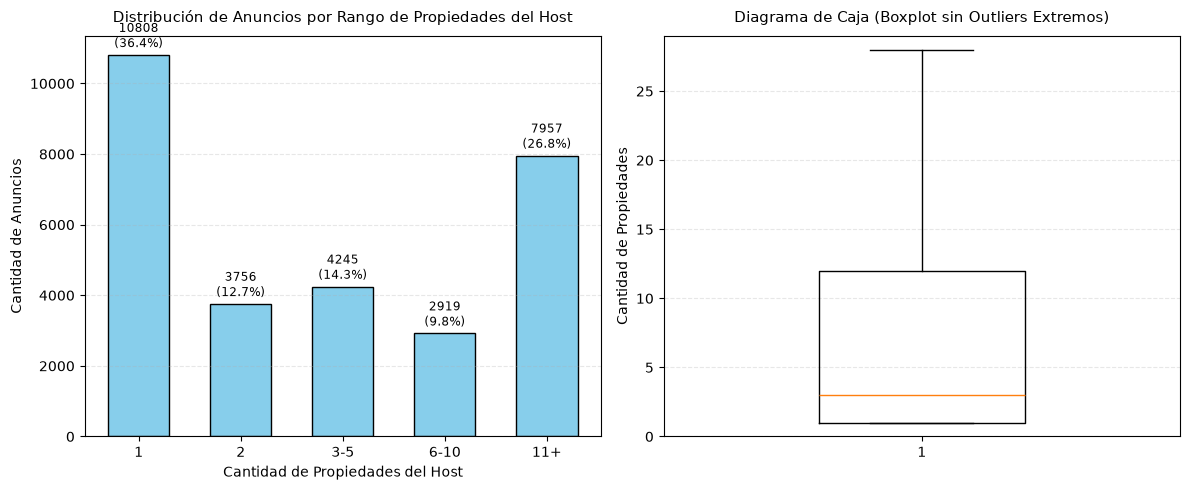

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# CALCULOS Y ESTADISTICAS DE MULTIPROPIEDAD
serie_host_listings = df_listings["calculated_host_listings_count"].dropna()
total_anuncios = len(serie_host_listings)

q1 = serie_host_listings.quantile(0.25)
mediana = serie_host_listings.median()  # Q2 (50%)
q3 = serie_host_listings.quantile(0.75)
ric = q3 - q1

# Porcentaje de multipropiedad (anuncios administrados por hosts con más de 1 listing)
multi_prop = (serie_host_listings > 1).sum()
pct_multi_prop = (multi_prop / total_anuncios) * 100

print("=== ANÁLISIS DE LA VARIABLE: calculated_host_listings_count"" (MULTIPROPIEDAD) ===")
print(f"N (Válidos): {total_anuncios}")
print(f"Q1 (25%): {q1:.2f}")
print(f"Mediana (Q2 - 50%): {mediana:.2f}")
print(f"Q3 (75%): {q3:.2f}")
print(f"Rango Intercuartílico (RIC): {ric:.2f}")
print(f"Anuncios en Multipropiedad (>1 listing): {multi_prop} ({pct_multi_prop:.2f}%)")
print("Anuncios de Propietario Único (=1 listing):"f" {total_anuncios - multi_prop} ({100 - pct_multi_prop:.2f}%)")

# GRÁFICOS DE BARRAS POR RANGOS Y BOXPLOT
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gráfico de Barras por Rangos
bins = [0, 1, 2, 5, 10, np.inf]
labels = ["1", "2", "3-5", "6-10", "11+"]
rangos = pd.cut(serie_host_listings, bins=bins, labels=labels, right=True)
counts_rangos = rangos.value_counts().sort_index()

axes[0].bar(counts_rangos.index.astype(str), counts_rangos.values, color="skyblue", edgecolor="black", width=0.6)
axes[0].set_title("Distribución de Anuncios por Rango de Propiedades del Host", fontsize=11, pad=10)
axes[0].set_xlabel("Cantidad de Propiedades del Host")
axes[0].set_ylabel("Cantidad de Anuncios")
axes[0].grid(axis="y", linestyle="--", alpha=0.3)

# Agregar etiquetas numéricas y porcentajes sobre cada barra
for j, val in enumerate(counts_rangos.values):
  pct = (val / total_anuncios) * 100
  axes[0].text(j, val + (max(counts_rangos.values) * 0.01), f"{val}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=8.5)

# Gráfico de Boxplot Optimizado
lim_sup = q3 + 1.5 * ric
bigote_sup = serie_host_listings[serie_host_listings <= lim_sup].max()

axes[1].boxplot(serie_host_listings, label=["Host Listings Count"], showfliers=False, widths=0.4)
axes[1].set_ylim(0, max(bigote_sup + 1, 2))
axes[1].set_title("Diagrama de Caja (Boxplot sin Outliers Extremos)", fontsize=11, pad=10)
axes[1].set_ylabel("Cantidad de Propiedades")
axes[1].grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### Analisis variables "minimum_nights", "maximum_nights" y "availability_365"

=== ANÁLISIS DE ESTADÍAS: minimum_nights Y maximum_nights ===

--- Variable: minimum_nights ---
Mediana (Q2 - 50%): 2.00 noches
Q1 (25%): 1.00 | Q3 (75%): 3.00
Rango Intercuartílico (RIC): 2.00 noches
Estadía Corta (<= 30 noches): 29338 anuncios (98.84%)
Estadía Extendida (> 30 noches): 344 anuncios (1.16%)

--- Variable: maximum_nights ---
Mediana (Q2 - 50%): 365.00 noches
Q1 (25%): 364.00 | Q3 (75%): 1125.00
Rango Intercuartílico (RIC): 761.00 noches
Estadía Corta (<= 30 noches): 2945 anuncios (9.92%)
Estadía Extendida (> 30 noches): 26737 anuncios (90.08%)

=== ANÁLISIS DE DISPONIBILIDAD: availability_365 ===
Media: 235.02 días
Mediana: 264.00 días
Desvío Estándar: 116.16 días
Anuncios Inactivos/Bloqueados (disponibilidad = 0 días): 1106 (3.73%)
Anuncios Activos (disponibilidad > 0 días): 28579 (96.27%)


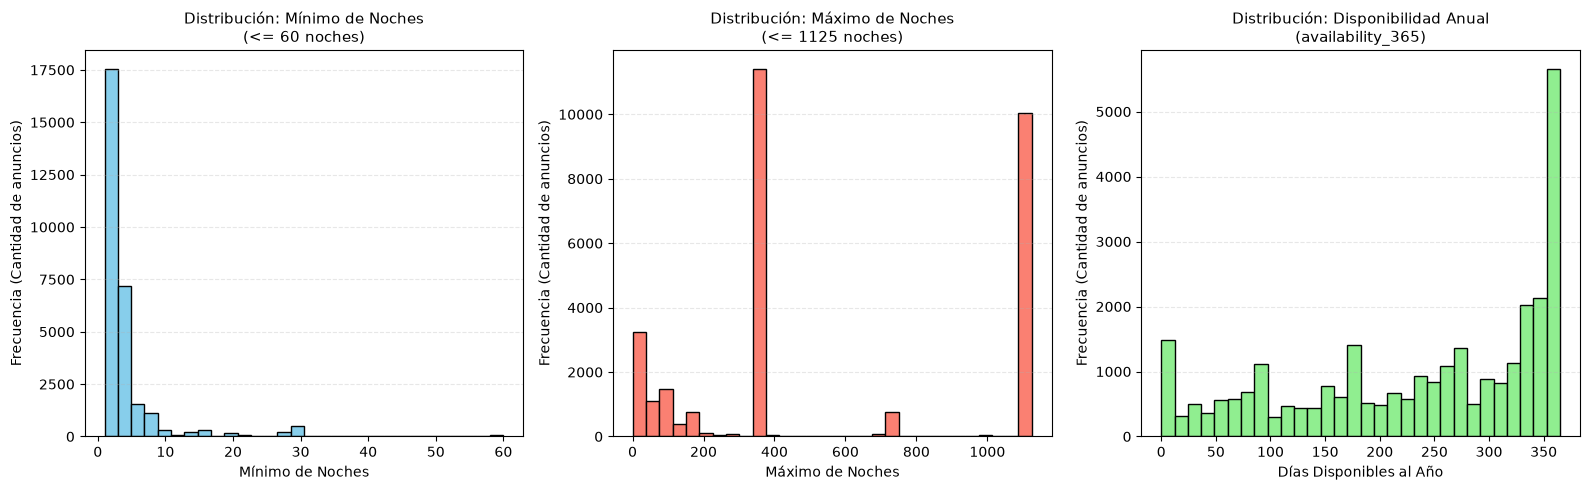

In [31]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# CÁLCULO DE ESTADÍSTICAS Y PROPORCIONES
vars_noches = ["minimum_nights", "maximum_nights"]

print("=== ANÁLISIS DE ESTADÍAS: minimum_nights Y maximum_nights ===")
for col in vars_noches:
  serie = df_listings[col].dropna()
  q1 = serie.quantile(0.25)
  mediana = serie.median()  # Q2 (50%)
  q3 = serie.quantile(0.75)
  ric = q3 - q1

  # Proporción Estadía Corta (<= 30 noches) vs Extendida (> 30 noches)
  corta = (serie <= 30).sum()
  extendida = (serie > 30).sum()
  pct_corta = (corta / len(serie)) * 100
  pct_extendida = (extendida / len(serie)) * 100

  print(f"\n--- Variable: {col} ---")
  print(f"Mediana (Q2 - 50%): {mediana:.2f} noches")
  print(f"Q1 (25%): {q1:.2f} | Q3 (75%): {q3:.2f}")
  print(f"Rango Intercuartílico (RIC): {ric:.2f} noches")
  print(f"Estadía Corta (<= 30 noches): {corta} anuncios ({pct_corta:.2f}%)")
  print(
      f"Estadía Extendida (> 30 noches): {extendida} anuncios"
      f" ({pct_extendida:.2f}%)"
  )

# Variable availability_365 
serie_avail = df_listings["availability_365"].dropna()
media_avail = serie_avail.mean()
mediana_avail = serie_avail.median()
std_avail = serie_avail.std()

inactivos = (serie_avail == 0).sum()
pct_inactivos = (inactivos / len(serie_avail)) * 100

print("\n" + "=" * 60)
print("=== ANÁLISIS DE DISPONIBILIDAD: availability_365 ===")
print(f"Media: {media_avail:.2f} días")
print(f"Mediana: {mediana_avail:.2f} días")
print(f"Desvío Estándar: {std_avail:.2f} días")
print(
    f"Anuncios Inactivos/Bloqueados (disponibilidad = 0 días): {inactivos}"
    f" ({pct_inactivos:.2f}%)"
)
print(
    f"Anuncios Activos (disponibilidad > 0 días):"
    f" {len(serie_avail) - inactivos} ({100 - pct_inactivos:.2f}%)"
)
print("=" * 60)

# HISTOGRAMAS DE FRECUENCIA
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Histograma de minimum_nights (limitado a <= 60 para visualizar el grueso de datos)
data_min = df_listings["minimum_nights"].dropna()
axes[0].hist(
    data_min[data_min <= 60], bins=30, color="skyblue", edgecolor="black"
)
axes[0].set_title(
    "Distribución: Mínimo de Noches\n(<= 60 noches)", fontsize=11
)
axes[0].set_xlabel("Mínimo de Noches")
axes[0].set_ylabel("Frecuencia (Cantidad de anuncios)")
axes[0].grid(axis="y", linestyle="--", alpha=0.3)

# Histograma de maximum_nights (limitado a <= 1125 para capturar rangos estándar)
data_max = df_listings["maximum_nights"].dropna()
axes[1].hist(
    data_max[data_max <= 1125], bins=30, color="salmon", edgecolor="black"
)
axes[1].set_title(
    "Distribución: Máximo de Noches\n(<= 1125 noches)", fontsize=11
)
axes[1].set_xlabel("Máximo de Noches")
axes[1].set_ylabel("Frecuencia (Cantidad de anuncios)")
axes[1].grid(axis="y", linestyle="--", alpha=0.3)

# Histograma de availability_365
axes[2].hist(serie_avail, bins=30, color="lightgreen", edgecolor="black")
axes[2].set_title(
    "Distribución: Disponibilidad Anual\n(availability_365)", fontsize=11
)
axes[2].set_xlabel("Días Disponibles al Año")
axes[2].set_ylabel("Frecuencia (Cantidad de anuncios)")
axes[2].grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### Analisis variable "review_scores_rating"

=== ANÁLISIS DE LA VARIABLE: review_scores_rating ===
Total de Anuncios: 29685
Anuncios Válidos con Puntuación: 25957 (87.44%)
Anuncios Faltantes/Sin Reservas (Nuevos): 3728 (12.56%)
Q1 (25%): 4.73
Mediana (Q2 - 50%): 4.87
Q3 (75%): 4.98
Rango Intercuartílico (RIC): 0.25


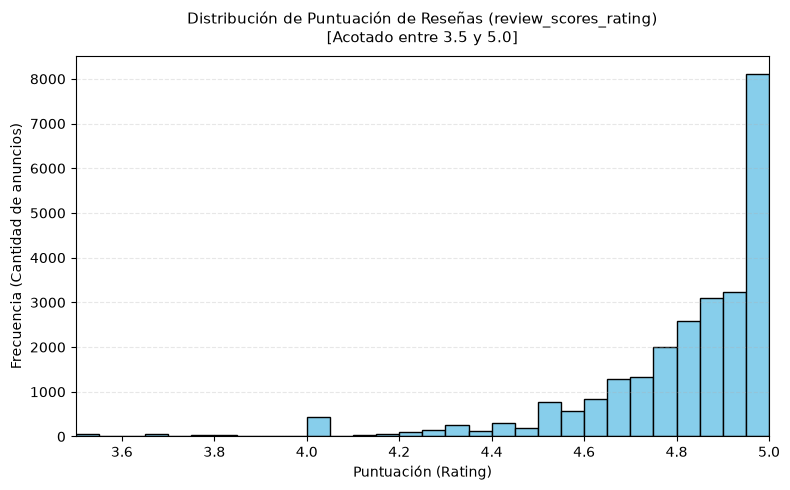

In [32]:
import matplotlib.pyplot as plt
import pandas as pd

# CÁLCULO DE ESTADÍSTICAS Y VALORES FALTANTES
col_rating = "review_scores_rating"
total_anuncios = len(df_listings)

# Serie completa con nulos para el análisis de faltantes
serie_completa = df_listings[col_rating]
nulos = serie_completa.isnull().sum()
pct_nulos = (nulos / total_anuncios) * 100

# Serie sin valores nulos para el cálculo de cuartiles
serie_validos = serie_completa.dropna()
total_validos = len(serie_validos)

q1 = serie_validos.quantile(0.25)
mediana = serie_validos.median()  # Q2 (50%)
q3 = serie_validos.quantile(0.75)
ric = q3 - q1

print(f"=== ANÁLISIS DE LA VARIABLE: {col_rating} ===")
print(f"Total de Anuncios: {total_anuncios}")
print(f"Anuncios Válidos con Puntuación: {total_validos}"f" ({100 - pct_nulos:.2f}%)")
print(f"Anuncios Faltantes/Sin Reservas (Nuevos): {nulos} ({pct_nulos:.2f}%)")
print(f"Q1 (25%): {q1:.2f}")
print(f"Mediana (Q2 - 50%): {mediana:.2f}")
print(f"Q3 (75%): {q3:.2f}")
print(f"Rango Intercuartílico (RIC): {ric:.2f}")

# HISTOGRAMA DE FRECUENCIAS ACOTADO ENTRE 3.5 Y 5.0
plt.figure(figsize=(8, 5))

# Filtrar datos en el rango especifico [3.5, 5.0]
rating_acotado = serie_validos[(serie_validos >= 3.5) & (serie_validos <= 5.0)]

plt.hist(rating_acotado, bins=30, color="skyblue", edgecolor="black")
plt.title("Distribución de Puntuación de Reseñas (review_scores_rating)\n[Acotado"" entre 3.5 y 5.0]", fontsize=11, pad=10)
plt.xlabel("Puntuación (Rating)")
plt.ylabel("Frecuencia (Cantidad de anuncios)")
plt.xlim(3.5, 5.0)
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

## Analisis Nulos

### Nulos - Codigo

In [2]:
import pandas as pd

# Buscar cadenas habituales de valores faltantes
valores_raros = ["?", "N/A", "NA", "null", "None", "", " ", "NS/NC", "Ignorado", "Sin dato", ".", "0", "-1", "\n", "{}", "[]", "$"]

# copiamos el conjunto para preservarlo
dataset = df_listings.copy()

colMin=0
colMax=46

# Cantidad Nulos
nulos_df = pd.DataFrame({
    "Nulos": dataset.iloc[:, colMin:colMax].isna().sum(),
    "Valores_raros": dataset.iloc[:, colMin:colMax].isin(valores_raros).sum(),
    "Ceros": (dataset.iloc[:, colMin:colMax] == 0).sum(),
    "Total Nulos": dataset.iloc[:, colMin:colMax].isna().sum() + dataset.iloc[:, colMin:colMax].isin(valores_raros).sum() + (dataset.iloc[:, colMin:colMax] == 0).sum()})

resultado = nulos_df[nulos_df["Total Nulos"] > 0]

print(resultado)

                              Nulos  Valores_raros  Ceros  Total Nulos
name                              0              1      0            1
description                     768              6      0          774
neighborhood_overview         29685              0      0        29685
picture_url                       1              0      0            1
host_since                    29685              0      0        29685
hosts_time_as_user_years          0              0   1129         1129
hosts_time_as_user_months         0              0   2402         2402
hosts_time_as_host_years          0              0   2813         2813
hosts_time_as_host_months         0              0   2290         2290
host_location                  6580              0      0         6580
host_about                    12938             61      0        12999
host_response_time            29685              0      0        29685
host_response_rate            29685              0      0        29685
host_a

In [3]:
import pandas as pd

# Buscar cadenas habituales de valores faltantes
valores_raros = ["?", "N/A", "NA", "null", "None", "", " ", "NS/NC", "Ignorado", "Sin dato", ".", "0", "-1", "\n", "{}", "[]", ""]

# copiamos el conjunto para preservarlo
dataset = df_listings.copy()

colMin=46
colMax=90

# Cantidad Nulos
nulos_df = pd.DataFrame({
    "Nulos": dataset.iloc[:, colMin:colMax].isna().sum(),
    "Valores_raros": dataset.iloc[:, colMin:colMax].isin(valores_raros).sum(),
    "Ceros": (dataset.iloc[:, colMin:colMax] == 0).sum(),
    "Total Nulos": dataset.iloc[:, colMin:colMax].isna().sum() + dataset.iloc[:, colMin:colMax].isin(valores_raros).sum() + (dataset.iloc[:, colMin:colMax] == 0).sum()
})

resultado = nulos_df[nulos_df["Total Nulos"] > 0]

print(resultado)

                                              Nulos  Valores_raros  Ceros  \
price                                          1792              0      0   
price_quote_checkin_date                       1338              0      0   
price_quote_checkout_date                      1338              0      0   
price_quote_total_price                        1792              0      0   
price_quote_price_per_night                    1792              0      0   
price_quote_raw                                1338              0      0   
minimum_nights                                    3              0      0   
maximum_nights                                    3              0      0   
minimum_minimum_nights                            3              0      0   
maximum_minimum_nights                            3              0      0   
minimum_maximum_nights                            3              0      0   
maximum_maximum_nights                            3              0      0   

### Analisis Nulos (1-30)

#### Metadatos
No aportan valor estadistico al ser enlaces o identificadores de scraping. Se deben eliminar.
* **"scrape_id"**
* **"last_scraped"**
* **"source"**
* **"listing_url"**
* **"picture_url"**
* **"host_url"**
* **"host_profile_id"**
* **"host_profile_url"**
* **"host_picture_url"**

#### Columnas vacias
No tienen datos, no aportan informacion para el analisis o las hipotesis.
* **"neighborhood_overview":**
    *  Nulos: 100%
    *  Preprocesado: eliminar columna
* **"host_since":**
    *  Nulos: 100%
    *  Preprocesado: eliminar columna
* **"host_response_time":**
    *  Nulos: 100%
    *  Preprocesado: eliminar columna
* **"host_response_rate":**
    *  Nulos: 100%
    *  Preprocesado: eliminar columna
* **"host_response_rate":**
    *  Nulos: 100%
    *  Preprocesado: eliminar columna
* **"host_thumbnail_url":**
    *  Nulos: 100%
    *  Preprocesado: eliminar columna
* **"host_neighbourhood":**
    *  Nulos: 100%
    *  Preprocesado: eliminar columna
* **"host_total_listings_count":**
    *  Nulos: 100%
    *  Preprocesado: eliminar columna
* **"host_acceptance_rate":**
    *  Nulos: 100%
    *  Preprocesado: eliminar columna

#### Mantener sin modificar
* **"id":**
    * Nulos: 0%
    * Preprocesado: Mantener como esta sin eliminar la columna.
* **"host_id":**
    * Nulos: 0%
    * Preprocesado: Mantener como esta sin eliminar la columna. Hay 61 valores 
* **"name":**
    * Nulos: 0%
    * Preprocesado: Mantener como esta sin eliminar la columna. 
* **"description":**
    * Nulos: 3%
    * Preprocesado: Mantener como esta sin eliminar la columna.  
* **"host_location":**
    * Nulos: 44%
    * Preprocesado: Mantener como esta sin eliminar la columna.  
* **"host_about":**
    * Nulos: 22%
    * Preprocesado:  Mantener sin eliminar la columna, no aporta informacion necesaria pero tienen 61 filas las cuales tienen ".". Estas reemplazarlas por NaN
* **"hosts_time_as_user_years":**
    * Nulos: 0
    * Preprocesado: Hay valores "0" (1129), que representan nulos. Representan 0 años con la aplicacion como usuario por los que se deben mantener. 
* **"hosts_time_as_user_months":**
    * Nulos: 0
    * Preprocesado: Hay valores "0" (2402), que representan nulos. Representan 0 meses con la aplicacion como usuario por los que se deben mantener.  
* **"hosts_time_as_host_years":**
    * Nulos: 0
    * Preprocesado: Hay valores "0" (2813), que representan nulos. Representan 0 años con la aplicacion como host por los que se deben mantener. 
* **"hosts_time_as_host_months":**
    * Nulos: 0
    * Preprocesado: Hay valores "0" (2290), que representan nulos. Representan 0 meses con la aplicacion como host por los que se deben mantener.
* **"host_name":**
    * Nulos: 0%
    * Preprocesado: Mantener como esta sin eliminar la columna

#### Modificar o transformar
* **"host_listings_count":**
    * Nulos: 0%
    * Preprocesado: Mantener como esta sin eliminar la columna. Hay 1 valor "0", es un caso aislado de inconsistencia del scraping donde una propiedad activa figura con 0 listings asociados. Reemplazar de "0" a "1"
* **"host_is_superhost":**
    * Nulos: 0%
    * Preprocesado: Transformar su tipo de dato de texto ("t"/"f") a booleano (True/False). 

### Analisis Nulos (62-90)

* 'has_availibility':
    * nulos: <1%
    * preprocesado: Pasar nulos a falso y cambiar a booleano.
* 'availibility_30':
    * nulos: 0%
    * preprocesado: se deja.
* 'availability_60':
    * nulos: 0%
    * preprocesado: se deja.
* 'availability_90':
    * nulos: 0%
    * preprocesado: se deja.
* 'availability_365':
    * nulos: 0%
    * preprocesado: se deja.
* 'calendar_last_scraped':
    * nulos: 0%
    * preprocesado: a eliminar por correlacion=1 con "last_scraped" (los datos son muuy parecidos)
* 'number_of_reviews':
    * nulos: 0%
    * preprocesado: se deja
* 'number_of_reviews_ltm':
    * nulos: 0%
    * preprocesado: se deja
* 'number_of_reviews_l30d':
    * nulos: 0%
    * preprocesado: se deja.
* 'availability_eoy':
    * nulos: 0%
    * preprocesado: se deja
* 'number_of_reviews_ly':
    * nulos: 0%
    * preprocesado: se deja.
* 'estimated_occupancy_l365d':
    * nulos: 0%
    * preprocesado: se deja.
* 'estimated_revenue_l365d':
    * nulos: 6%
    * preprocesado: eliminar nulos.
* 'first_review':
    * nulos: 13% + 12.56%(Nan/None)
    * preprocesado: cambiar por la mediana los nulos y cambiar a formato fecha.
* 'last_review':
    * nulos: 13% + 12.56%(Nan/None)
    * preprocesado: cambiar por la mediana los nulos y cambiar a formato fecha.
* 'review_scores_rating':
    * nulos: 13%
    * preprocesado: cambiar por la mediana los nulos.
* 'review_scores_accuracy':
    * nulos: 13%
    * preprocesado: cambiar por la mediana los nulos.
* 'review_scores_cleanliness':
    * nulos: 13%
    * preprocesado: cambiar por la mediana los nulos.
* 'review_scores_checkin':
    * nulos: 13%
    * preprocesado: cambiar por la mediana los nulos.
* 'review_scores_communication':
    * nulos: 13%
    * preprocesado: cambiar por la mediana los nulos.
* 'review_scores_location':
    * nulos: 13%
    * preprocesado: cambiar por la mediana los nulos.
* 'review_scores_value':
    * nulos: 13%
    * preprocesado: cambiar por la mediana los nulos.
* 'license':
    * nulos: 98%
    * preprocesado: eliminar variable.
* 'instant_bookable':
    * nulos: 100%
    * preprocesado: eliminar variable.
* 'calculated_host_listings_count':
    * nulos: 0%
    * preprocesado: se deja.
* 'calculated_host_listings_count_entire_homes':
    * nulos: 0%
    * preprocesado: se deja.
* 'calculated_host_listings_count_private_rooms':
    * nulos: 0%
    * preprocesado: se deja.
* 'calculated_host_listings_count_shared_rooms':
    * nulos: 0%
    * preprocesado: se deja.
* 'reviews_per_month':
    * nulos: 13%
    * preprocesado: cambiar por la mediana los nulos.


# Punto 2

## Valores Raros

* **has_availability:** Variable str la cual esta llena de "t", con 195 NaN, los cuales los interpretamos como "False". La vamos a volver boolean donde "t": True y "NaN": False
* **amenities:** Tiene 6 valores raros los cuales son "[]", representan NaN.
* **host_about:** 61 valores son "." que representan NaN. No la limpiamos al no ser importante.
* **description:** 6 valores son "." que representan NaN. No la limpiamos al no ser importante.
* **name:** 1 valores son "." que representan NaN. No la limpiamos al no ser importante.
* **license:** Tiene varios valores raros como "0", "1" o numeros de telefonos. No la limpiamos al no ser importante.

In [ ]:
col_name = "license"
dataset[col_name][dataset[col_name].isin(valores_raros)].unique().tolist()

## Preproceado (variables 62-90)

In [ ]:
import pandas as pd

# Crear la copia de trabajo a partir del dataset original
preprocessed_listings = df_listings.copy()

# Eliminar filas con valores nulos en la columna de ingresos estimados 
preprocessed_listings = preprocessed_listings.dropna(subset=["estimated_revenue_l365d"])

# Rellenar nulos con 'f' y convertir a True/False según si es igual a 't'
preprocessed_listings["has_availability"] = (preprocessed_listings["has_availability"].fillna("f") == "t" )

# Convertir 'first_review' y 'last_review' a fecha e imputar TODOS los nulos/NaT con la mediana
for col_fecha in ["first_review", "last_review"]:
  if col_fecha in preprocessed_listings.columns:
    preprocessed_listings[col_fecha] = pd.to_datetime(preprocessed_listings[col_fecha], errors="coerce")
    mediana_fecha = preprocessed_listings[col_fecha].median()
    preprocessed_listings[col_fecha] = preprocessed_listings[col_fecha].fillna(mediana_fecha)

# Imputar valores nulos con la mediana en puntuaciones y reviews_per_month
cols_mediana = ["review_scores_rating", "review_scores_accuracy", "review_scores_cleanliness", "review_scores_checkin", "review_scores_communication", "review_scores_location", "review_scores_value", "reviews_per_month"]

for col in cols_mediana:
  if col in preprocessed_listings.columns:
    mediana_val = preprocessed_listings[col].median()
    preprocessed_listings[col] = preprocessed_listings[col].fillna(mediana_val)

# Eliminar directamente las columnas 'license' e 'instant_bookable'
cols_a_eliminar = ["license", "instant_bookable"]
preprocessed_listings = preprocessed_listings.drop(columns=cols_a_eliminar, errors="ignore")